   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  StockOptionLevel  \
0  ...

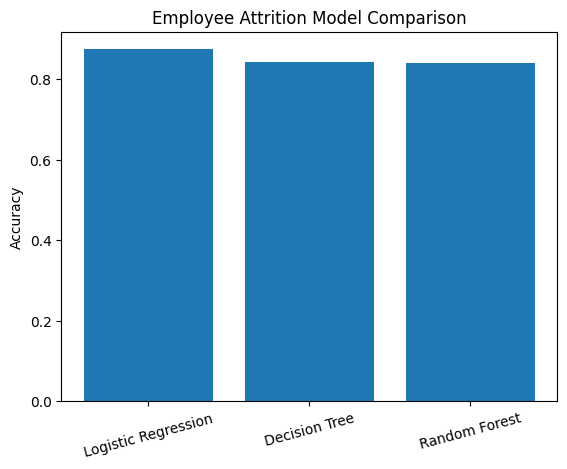

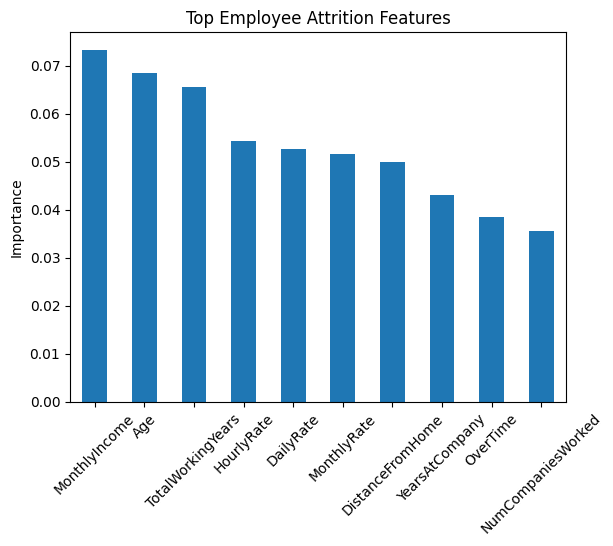


Logistic Regression performed best.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

data = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

print(data.head())
print(data.isnull().sum())

data = data.drop(["EmployeeCount", "EmployeeNumber", "Over18", "StandardHours"], axis=1)

le = LabelEncoder()

for column in data.select_dtypes(include="object").columns:
    data[column] = le.fit_transform(data[column])

X = data.drop("Attrition", axis=1)
y = data["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

logistic = LogisticRegression(max_iter=1000)
tree = DecisionTreeClassifier(random_state=42, max_depth=5)
forest = RandomForestClassifier(n_estimators=100, random_state=42)

logistic.fit(X_train, y_train)
tree.fit(X_train, y_train)
forest.fit(X_train, y_train)

logistic_pred = logistic.predict(X_test)
tree_pred = tree.predict(X_test)
forest_pred = forest.predict(X_test)

logistic_accuracy = accuracy_score(y_test, logistic_pred)
tree_accuracy = accuracy_score(y_test, tree_pred)
forest_accuracy = accuracy_score(y_test, forest_pred)

print("\nLogistic Regression Accuracy:", logistic_accuracy)
print("Decision Tree Accuracy:", tree_accuracy)
print("Random Forest Accuracy:", forest_accuracy)

print("\nLogistic Regression Confusion Matrix")
print(confusion_matrix(y_test, logistic_pred))

print("\nDecision Tree Confusion Matrix")
print(confusion_matrix(y_test, tree_pred))

print("\nRandom Forest Confusion Matrix")
print(confusion_matrix(y_test, forest_pred))

print("\nF1 Scores")
print("Logistic Regression:", f1_score(y_test, logistic_pred))
print("Decision Tree:", f1_score(y_test, tree_pred))
print("Random Forest:", f1_score(y_test, forest_pred))

models = ["Logistic Regression", "Decision Tree", "Random Forest"]
accuracy = [logistic_accuracy, tree_accuracy, forest_accuracy]

plt.bar(models, accuracy)
plt.ylabel("Accuracy")
plt.title("Employee Attrition Model Comparison")
plt.xticks(rotation=15)
plt.show()

importance = pd.Series(
    forest.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

importance.head(10).plot(kind="bar")
plt.title("Top Employee Attrition Features")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.show()

if forest_accuracy >= tree_accuracy and forest_accuracy >= logistic_accuracy:
    print("\nRandom Forest performed best.")
elif tree_accuracy >= logistic_accuracy:
    print("\nDecision Tree performed best.")
else:
    print("\nLogistic Regression performed best.")